# 05 · Estacionalidad descriptiva (P6)

**Objetivo:** identificar qué productos muestran un patrón estacional estable de precios
**Preguntas que responde:** P6
**Entrada:** `data/processed/precios_limpio.parquet`
**Salida:** `images/p6_estacionalidad.png` (en la siguiente tanda)
**Decisiones tomadas:** D-07, D-18 (se cierra aquí)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/processed/precios_limpio.parquet")

MIN_OBS = 5          # filas mínimas por mes y serie
MIN_MESES_ANIO = 6   # meses con dato para que una serie-año entre
MIN_MERCADOS = 3     # mercados mínimos por producto, año y mes

b = df[df["anio"] <= 2025].copy()
for c in ["producto", "mercado", "unidad"]:
    b[c] = b[c].astype(str)
b["mes"] = b["fecha"].dt.month

mu = (b.groupby(["producto", "mercado", "unidad", "anio", "mes"])
        .agg(precio=("precio_prom", "median"), n=("precio_prom", "size")).reset_index())
mu = mu[mu["n"] >= MIN_OBS]

# una sola etiqueta por (producto, mercado): la de más meses
meses = mu.groupby(["producto", "mercado", "unidad"]).size().rename("meses").reset_index()
dom = meses.sort_values("meses", ascending=False).drop_duplicates(["producto", "mercado"])
s = mu.merge(dom[["producto", "mercado", "unidad"]], on=["producto", "mercado", "unidad"])
s["lp"] = np.log(s["precio"])

g = s.groupby(["producto", "mercado", "anio"])["lp"]
s["k"] = g.transform("size")
s["dev"] = s["lp"] - g.transform("mean")
s = s[s["k"] >= MIN_MESES_ANIO]

prof = (s.groupby(["producto", "anio", "mes"])
          .agg(dev=("dev", "median"), mercados=("mercado", "nunique")).reset_index())
prof = prof[prof["mercados"] >= MIN_MERCADOS]

print("series-año:", s.groupby(["producto", "mercado", "anio"]).ngroups,
      "| productos:", s["producto"].nunique(),
      "| celdas producto-año-mes con 3+ mercados:", len(prof),
      "| productos:", prof["producto"].nunique())

series-año: 2227 | productos: 69 | celdas producto-año-mes con 3+ mercados: 2897 | productos: 53


In [3]:
def estabilidad(M, min_meses=5):
    cors = []
    for y in M.index:
        otros = M.drop(index=y).mean(axis=0, skipna=True)
        x = M.loc[y]
        ok = x.notna() & otros.notna()
        if ok.sum() >= min_meses and x[ok].std() > 0 and otros[ok].std() > 0:
            cors.append(np.corrcoef(x[ok], otros[ok])[0, 1])
    return (float(np.mean(cors)), len(cors)) if len(cors) >= 3 else (np.nan, len(cors))

filas, mats = [], {}
for p, d in prof.groupby("producto"):
    M = d.pivot(index="anio", columns="mes", values="dev")
    perfil = M.mean(axis=0, skipna=True).dropna()
    est, nanios = estabilidad(M)
    if len(perfil) < 6 or np.isnan(est):
        continue
    mats[p] = M
    filas.append(dict(producto=p, anios=nanios, meses=len(perfil), estabilidad=est,
                      amplitud_pct=(np.exp(perfil.max() - perfil.min()) - 1) * 100,
                      mes_pico=int(perfil.idxmax()), mes_valle=int(perfil.idxmin())))
res = pd.DataFrame(filas).sort_values("estabilidad", ascending=False).reset_index(drop=True)
print("productos evaluables:", len(res), "de", prof["producto"].nunique())

rng = np.random.default_rng(42)
nulos = []
for p, M in mats.items():
    for _ in range(100):
        Mp = M.copy()
        for y in Mp.index:
            v = Mp.loc[y].dropna().values
            Mp.loc[y, Mp.loc[y].notna()] = rng.permutation(v)
        e, _ = estabilidad(Mp)
        if not np.isnan(e):
            nulos.append(e)
q95 = float(np.percentile(nulos, 95))
print("estabilidad esperada por azar: mediana", round(float(np.median(nulos)), 2),
      "| percentil 95:", round(q95, 2))
for u in [0.5, 0.7, q95]:
    print(f"estabilidad >= {u:.2f}:", int((res["estabilidad"] >= u).sum()))
print(res.round(2).to_string(index=False))

productos evaluables: 44 de 53
estabilidad esperada por azar: mediana 0.01 | percentil 95: 0.31
estabilidad >= 0.50: 26
estabilidad >= 0.70: 14
estabilidad >= 0.31: 37
        producto  anios  meses  estabilidad  amplitud_pct  mes_pico  mes_valle
           Limón      6     12         0.98        378.13         3          8
 Arándano (blue)      4      9         0.95        275.69         9          2
        Frutilla      6     12         0.95        157.98         8         11
  Poroto granado      4      6         0.95         36.61        12          3
         Manzana      6     12         0.92         71.48         1          7
            Pera      6     12         0.91         56.12        12          5
       Alcachofa      6      8         0.91         95.00         6         10
            Haba      6      9         0.89        116.97         5         10
         Naranja      6     12         0.88        117.78         4          8
         Zapallo      6     12         0.8

In [4]:
import warnings

def estab_np(A, min_meses=5):
    cors = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        for i in range(A.shape[0]):
            otros = np.nanmean(np.delete(A, i, axis=0), axis=0)
            x = A[i]
            ok = ~np.isnan(x) & ~np.isnan(otros)
            if ok.sum() >= min_meses and x[ok].std() > 0 and otros[ok].std() > 0:
                cors.append(np.corrcoef(x[ok], otros[ok])[0, 1])
    return (float(np.mean(cors)), len(cors)) if len(cors) >= 3 else (np.nan, len(cors))

def evaluar(prof, nrep=200, seed=42):
    rng = np.random.default_rng(seed)
    filas = []
    for p, d in prof.groupby("producto"):
        M = d.pivot(index="anio", columns="mes", values="dev").reindex(columns=range(1, 13))
        A = M.values.astype(float)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            perfil = np.nanmean(A, axis=0)
        ok = ~np.isnan(perfil)
        est, nanios = estab_np(A)
        if ok.sum() < 6 or np.isnan(est):
            continue
        mayor, total = 0, 0
        for _ in range(nrep):
            B = A.copy()
            for i in range(B.shape[0]):
                idx = np.where(~np.isnan(B[i]))[0]
                B[i, idx] = rng.permutation(B[i, idx])
            e, _ = estab_np(B)
            if not np.isnan(e):
                total += 1
                mayor += e >= est
        pf = perfil[ok]
        filas.append(dict(producto=p, anios=nanios, meses=int(ok.sum()), estabilidad=est,
                          amplitud_pct=(np.exp(pf.max() - pf.min()) - 1) * 100,
                          mes_pico=int(np.argmax(np.where(ok, perfil, -np.inf)) + 1),
                          mes_valle=int(np.argmin(np.where(ok, perfil, np.inf)) + 1),
                          p_azar=(mayor + 1) / (total + 1)))
    return pd.DataFrame(filas).sort_values("estabilidad", ascending=False).reset_index(drop=True)

res1 = evaluar(prof)

comun = prof.groupby(["anio", "mes"])["dev"].median().rename("comun").reset_index()
prof_adj = prof.merge(comun, on=["anio", "mes"])
prof_adj["dev"] = prof_adj["dev"] - prof_adj["comun"]
res2 = evaluar(prof_adj)

cols = ["producto", "estabilidad", "amplitud_pct", "mes_pico", "mes_valle", "p_azar"]
cmp_ = res1[cols].merge(res2[cols], on="producto", suffixes=("", "_adj"))
cmp_["cambio"] = cmp_["estabilidad_adj"] - cmp_["estabilidad"]
pd.set_option("display.width", 220)
print(cmp_.round(2).to_string(index=False))

for nom, r_ in [("original", res1), ("sin movimiento común", res2)]:
    print(f"{nom}: evaluables {len(r_)}"
          f" | estab>=0.7 y p<=0.05: {int(((r_.estabilidad >= 0.7) & (r_.p_azar <= 0.05)).sum())}"
          f" | estab 0.5-0.7 y p<=0.05: {int(((r_.estabilidad >= 0.5) & (r_.estabilidad < 0.7) & (r_.p_azar <= 0.05)).sum())}"
          f" | p<=0.05: {int((r_.p_azar <= 0.05).sum())}")
print("meses pico (original):", res1["mes_pico"].value_counts().sort_index().to_dict())
print("meses valle (original):", res1["mes_valle"].value_counts().sort_index().to_dict())
print("no evaluables:", sorted(set(prof["producto"]) - set(res1["producto"])))

        producto  estabilidad  amplitud_pct  mes_pico  mes_valle  p_azar  estabilidad_adj  amplitud_pct_adj  mes_pico_adj  mes_valle_adj  p_azar_adj  cambio
           Limón         0.98        378.13         3          8    0.00             0.99            407.38             3              8        0.00    0.00
 Arándano (blue)         0.95        275.69         9          2    0.00             0.95            251.62             9              2        0.00   -0.00
        Frutilla         0.95        157.98         8         11    0.00             0.96            156.28             8             11        0.00    0.01
  Poroto granado         0.95         36.61        12          3    0.00             0.91             36.73            12              3        0.00   -0.03
         Manzana         0.92         71.48         1          7    0.00             0.90             80.27             1              7        0.00   -0.01
            Pera         0.91         56.12        12     

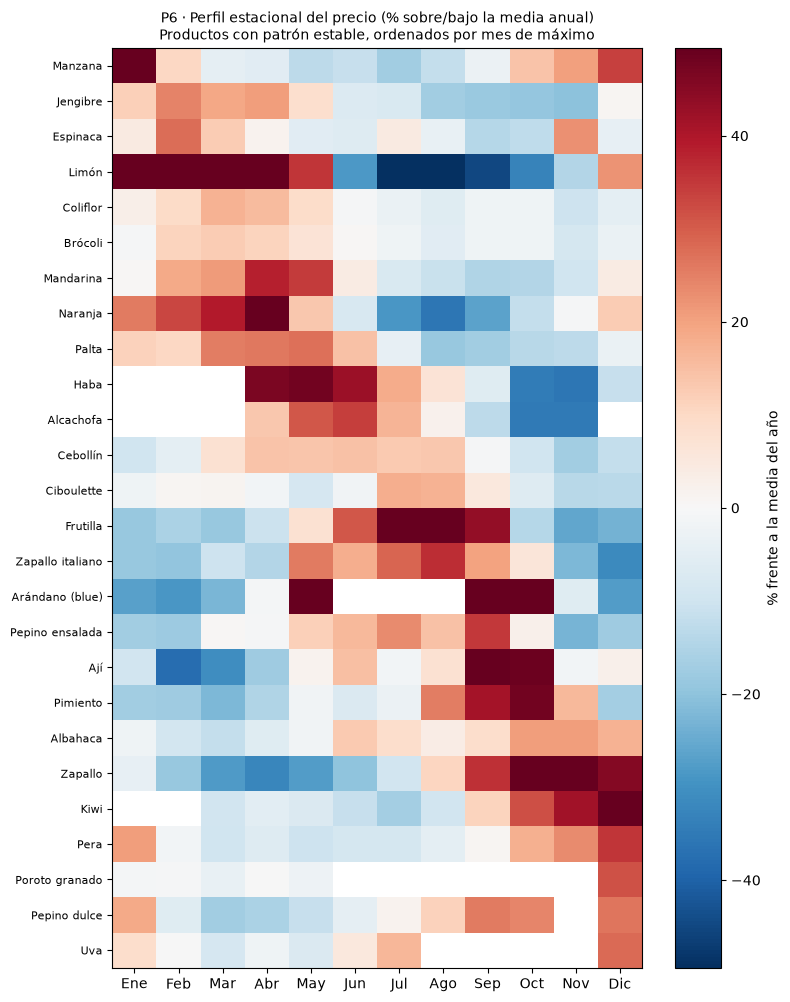

In [5]:
sel = res2[(res2["estabilidad"] >= 0.5) & (res2["p_azar"] <= 0.05)].sort_values("mes_pico")
filas = []
for p in sel["producto"]:
    M = prof_adj[prof_adj["producto"] == p].pivot(index="anio", columns="mes", values="dev")
    perfil = M.mean(axis=0, skipna=True).reindex(range(1, 13))
    filas.append((np.exp(perfil) - 1) * 100)
H = pd.DataFrame(filas, index=sel["producto"].values, columns=range(1, 13))

fig, ax = plt.subplots(figsize=(8, 0.32 * len(H) + 1.8))
lim = float(np.nanpercentile(np.abs(H.values), 95))
im = ax.imshow(np.ma.masked_invalid(H.values), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(12))
ax.set_xticklabels(["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.set_yticks(range(len(H)))
ax.set_yticklabels(H.index, fontsize=8)
ax.set_title("P6 · Perfil estacional del precio (% sobre/bajo la media anual)\n"
             "Productos con patrón estable, ordenados por mes de máximo", fontsize=10)
fig.colorbar(im, ax=ax, label="% frente a la media del año")
fig.tight_layout()
fig.savefig("../images/p6_estacionalidad.png", dpi=150)

In [6]:
fuera = sorted(set(df["producto"].astype(str)) - set(res1["producto"]))
m_fuera = mu[mu["producto"].isin(fuera)]
cal = (m_fuera.groupby(["producto", "mes"])["anio"].nunique()
         .unstack(fill_value=0).reindex(columns=range(1, 13), fill_value=0))
cal["mercados"] = m_fuera.groupby("producto")["mercado"].nunique()
print(len(fuera), "productos sin evaluar de", df["producto"].nunique())
print(cal.to_string())
print("sin ningún mes con 5+ filas:", sorted(set(fuera) - set(cal.index)))

38 productos sin evaluar de 82
mes                   1  2  3  4  5  6  7  8  9  10  11  12  mercados
producto                                                             
Achicoria             4  5  5  5  6  6  5  5  5   4   4   4         4
Arveja Verde          6  5  5  4  5  6  6  6  6   6   6   6         9
Breva                 0  0  1  1  1  0  0  0  0   0   1   2         4
Bruselas (repollito)  0  0  3  6  6  6  6  6  6   2   0   0         5
Caigua                0  0  0  0  2  2  3  5  4   4   1   2         2
Camote                5  4  6  4  6  4  4  6  5   4   6   4         3
Caqui                 0  0  0  6  6  6  1  0  0   0   0   0        10
Cebollín baby         1  4  2  2  3  1  2  2  3   4   0   2         1
Cereza                6  4  0  0  0  0  0  0  0   2   6   6        11
Chirimoya             0  0  0  0  0  3  6  6  6   6   6   6        10
Ciruela               6  6  6  6  6  6  1  0  0   0   0   6        11
Coco                  1  1  2  4  3  5  6  4  4   5   4   3

# Conclusiones de P6

## P6 · ¿Qué productos muestran un patrón estacional estable, con los mismos meses de precio alto y bajo en años distintos?

**Qué esperaba.** Sin hipótesis previa registrada.

**Cómo se midió.** Para cada serie (producto y mercado, una sola etiqueta) y año, la desviación del precio mensual (en logaritmos) respecto de la media del año. Mediana entre mercados (3 o más) por producto, año y mes. *Estabilidad:* correlación entre el perfil de cada año y el promedio de los demás años, promediada. *Amplitud:* cuánto más caro es el mes más caro que el más barato del perfil promedio. *Referencia de azar:* 200 mezclas de los meses dentro de cada año, por producto (`p_azar`). Los precios son nominales, así que se restó de cada año y mes la mediana entre productos (movimiento común): sin ese ajuste, la inflación puede hacer pasar por estacional un producto que no lo es (en una prueba con datos sintéticos, productos sin estacionalidad dieron una estabilidad de 0,92 a 0,95).

**Qué encontré.** De los 82 productos, 44 se pudieron evaluar. Tras el ajuste:

| Grupo | Criterio | Productos |
| --- | --- | ---: |
| Fuerte | estabilidad ≥ 0,70 y p_azar ≤ 0,05 | 16 |
| Moderado | estabilidad entre 0,50 y 0,70 y p_azar ≤ 0,05 | 10 |
| Débil | p_azar ≤ 0,05, estabilidad menor a 0,50 | 11 |
| Sin evidencia | p_azar > 0,05 | 7 |

**Ventana de oferta de las frutas de temporada corta (sin evaluar en estabilidad de precios).** En ocho de ellas, los meses centrales de su ventana aparecen los seis años: cereza (noviembre a febrero), ciruela (diciembre a junio), damasco (noviembre a enero), durazno (octubre a abril), nectarín (noviembre a abril), frambuesa (noviembre a junio), caqui (abril a junio) y espárragos (septiembre a diciembre). Esto describe cuándo se transan, no cómo se mueve su precio.

Productos con patrón fuerte (meses de 1 = enero a 12 = diciembre; amplitud en %):

| Producto | Estabilidad | Amplitud | Mes de máximo | Mes de mínimo |
| --- | ---: | ---: | --- | --- |
| Limón | 0,99 | 407 | marzo | agosto |
| Frutilla | 0,96 | 156 | agosto | noviembre |
| Arándano (blue) | 0,95 | 252 | septiembre | febrero |
| Alcachofa | 0,93 | 106 | junio | noviembre |
| Haba | 0,92 | 130 | mayo | noviembre |
| Poroto granado | 0,91 | 37 | diciembre | marzo |
| Manzana | 0,90 | 80 | enero | julio |
| Naranja | 0,90 | 138 | abril | agosto |
| Pera | 0,88 | 51 | diciembre | mayo |
| Mandarina | 0,87 | 62 | abril | septiembre |
| Zapallo | 0,86 | 163 | noviembre | abril |
| Kiwi | 0,77 | 95 | diciembre | julio |
| Ají | 0,77 | 172 | septiembre | febrero |
| Pepino dulce | 0,75 | 53 | diciembre | marzo |
| Cebollín | 0,75 | 38 | junio | noviembre |
| Coliflor | 0,74 | 30 | marzo | noviembre |

- Moderado: Albahaca, Ciboulette, Zapallo italiano, Palta, Uva, Pepino ensalada, Pimiento, Espinaca, Brócoli y Jengibre.
- Débil: Piña, Betarraga, Mango, Plátano, Zanahoria, Papa, Lechuga, Cilantro, Repollo, Acelga y Ajo.
- Sin evidencia: Poroto verde, Choclo, Apio, Tomate, Cebolla, Perejil y Berenjena.
- Los 14 productos más estables antes del ajuste siguen siéndolo después (todos sobre 0,75). Cambia el tramo medio: Piña, Betarraga y Mango bajan, y Coliflor, Brócoli, Jengibre y Acelga suben.
- Los meses de máximo del grupo fuerte se reparten durante el año (cuatro de los 16 caen en diciembre).

**Respuesta.** 26 de los 44 productos evaluables (59%) muestran un patrón estacional estable, 16 de ellos fuerte, con amplitudes de entre 30% y 407%. Tomate, cebolla y papa, tres de los productos de mayor volumen, no muestran estacionalidad estable.

**Preguntas de inferencia**

*¿Por qué ajustar por el movimiento común?* Porque con precios nominales, el alza dentro del año se repite y se lee como estabilidad. El ajuste inflaba a Piña (de 0,66 a 0,38) y ocultaba a Coliflor, Brócoli, Jengibre y Acelga, cuyo patrón va en contra de la deriva.

*¿Cómo sé que no es azar?* Comparo la estabilidad observada con la que saldría mezclando los meses al azar dentro de cada año, producto por producto. Un `p_azar` de 0,01 significa que solo 1% de las mezclas iguala lo observado.

*¿Qué significa una estabilidad de 0,9?* Que el perfil mensual de cada año se parece casi por completo al promedio de los demás años.

*¿Qué no responde?* No explica por qué ocurre ni predice nada. No es un modelo de series de tiempo.

**Limitaciones.** Solo 44 de los 82 productos se pudieron evaluar. Las frutas de temporada corta (ciruela, nectarín, chirimoya, tuna y pomelo entre ellas) quedan fuera de la medida de estabilidad de precios, y cuatro productos con datos todo el año (arveja verde, pomelo, rabanito y tuna) quedaron fuera por los filtros de mercados y meses, no por la temporada. Los precios son nominales y el ajuste por movimiento común es conservador: también quita cualquier patrón compartido por todos los productos en un mes, y cuatro máximos caen en diciembre, donde un resto de deriva produciría uno. Los perfiles de productos de temporada parcial cubren solo sus meses con datos. El mes de máximo es frágil en los grupos débiles. Las amplitudes están sesgadas al alza para productos ruidosos.

In [7]:
ipc = pd.read_csv("../data/external/ipc_ine.csv")
ipc["anio"] = ipc["mes"].str[:4].astype(int)
ipc["m"] = ipc["mes"].str[5:7].astype(int)
assert len(ipc) == 72 and not ipc["ipc"].isna().any(), "faltan meses o valores"

salto = ipc["ipc"].pct_change().abs().max()
assert salto < 0.03, f"salto mensual de {salto:.1%}: ¿mezcla de bases?"

dic = ipc[ipc["m"] == 12].set_index("anio")["ipc"]
infl = (dic.pct_change() * 100).dropna()
oficial = {2023: 3.9, 2024: 4.5, 2025: 3.5}
for a, o in oficial.items():
    assert abs(infl[a] - o) <= 0.15, f"{a}: {infl[a]:.2f}% frente a {o}% oficial"
print("inflación diciembre a diciembre (%):", infl.round(2).to_dict())

print(ipc.groupby("anio")["ipc"].agg(["count", "median"]).round(2))
fac = ipc[ipc["anio"] == 2025]["ipc"].median() / ipc[ipc["anio"] == 2020]["ipc"].median()
infl_pct = (fac - 1) * 100
print(f"IPC mediano 2025 / 2020: {fac:.3f} (+{infl_pct:.1f}%)")

inflación diciembre a diciembre (%): {2021: 7.16, 2022: 12.79, 2023: 3.94, 2024: 4.53, 2025: 3.45}
      count  median
anio               
2020     12   79.14
2021     12   82.37
2022     12   92.92
2023     12   99.51
2024     12  103.85
2025     12  108.37
IPC mediano 2025 / 2020: 1.369 (+36.9%)


In [8]:
s4 = s.merge(ipc[["anio", "m", "ipc"]].rename(columns={"m": "mes"}), on=["anio", "mes"])
s4["precio_real"] = s4["precio"] / s4["ipc"] * 100

def med_anio(y):
    t = s4[s4["anio"] == y].groupby(["producto", "mercado"])
    return t.agg(**{f"nom{y}": ("precio", "median"), f"real{y}": ("precio_real", "median"),
                    f"k{y}": ("precio", "size")})

c = med_anio(2020).join(med_anio(2025), how="inner")
c = c[(c["k2020"] >= 9) & (c["k2025"] >= 9)].reset_index()
c["l_nom"] = np.log(c["nom2025"] / c["nom2020"])
c["l_real"] = np.log(c["real2025"] / c["real2020"])
print("series con ambos años:", len(c), "| productos:", c["producto"].nunique())
print("mediana entre series: nominal", round((np.exp(c["l_nom"].median()) - 1) * 100, 1),
      "% | real", round((np.exp(c["l_real"].median()) - 1) * 100, 1), "%")

series con ambos años: 228 | productos: 43
mediana entre series: nominal 26.3 % | real -7.5 %


In [9]:
g = c.groupby("producto")
p = pd.DataFrame({
    "mercados": g["mercado"].nunique(),
    "nominal_pct": (np.exp(g["l_nom"].median()) - 1) * 100,
    "real_pct": (np.exp(g["l_real"].median()) - 1) * 100,
    "pct_mercados_suben": g["l_real"].apply(lambda x: (x > 0).mean() * 100),
})
p = p[p["mercados"] >= 3]

def clasificar(p, umbral):
    cl = pd.Series("sin cambio claro", index=p.index)
    cl[(p["real_pct"] > umbral) & (p["pct_mercados_suben"] >= 67)] = "sube"
    cl[(p["real_pct"] < -umbral) & (p["pct_mercados_suben"] <= 33)] = "baja"
    return cl

p["clase"] = clasificar(p, 10)
print(p.sort_values("real_pct").round(1).to_string())
for u in [5, 10, 15]:
    print(f"umbral {u}%:", clasificar(p, u).value_counts().to_dict())
print(f"productos: {len(p)} | nominal mediano {p['nominal_pct'].median():.1f}% | "
      f"inflación {infl_pct:.1f}% | real mediano {p['real_pct'].median():.1f}%")
print("productos cuyo cambio nominal no alcanzó a la inflación:",
      int((p["nominal_pct"] < infl_pct).sum()), "de", len(p))

                 mercados  nominal_pct  real_pct  pct_mercados_suben             clase
producto                                                                              
Papa                   10         -8.6     -33.3                 0.0              baja
Zapallo                 9         -7.7     -32.6                 0.0              baja
Palta                   3         -5.0     -30.3                 0.0              baja
Cebolla                 5          3.3     -24.7                20.0              baja
Frutilla                6          1.5     -24.4                 0.0              baja
Ciboulette              4          3.9     -24.3                 0.0              baja
Naranja                 6          7.5     -21.5                 0.0              baja
Ajo                     7         11.7     -18.6                28.6              baja
Mandarina               3         11.5     -18.3                 0.0              baja
Pimiento                8         12.9     

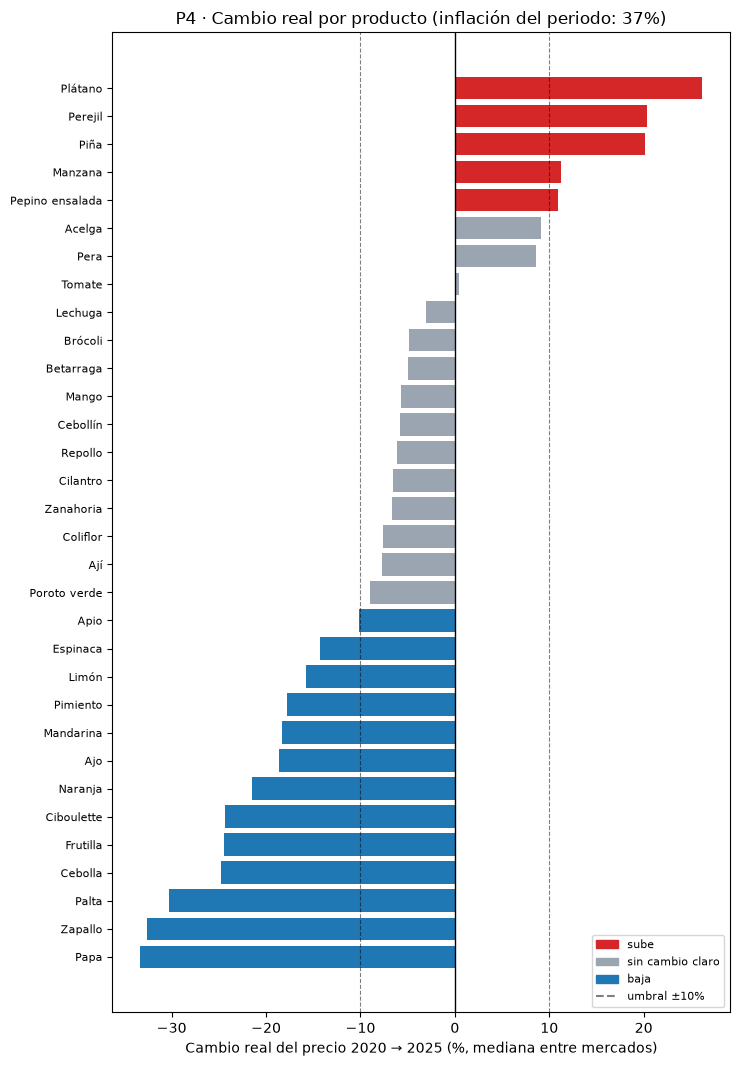

In [11]:
from matplotlib.patches import Patch

q = p.sort_values("real_pct")
paleta = {"sube": "#d62728", "baja": "#1f77b4", "sin cambio claro": "#9aa5b1"}
fig, ax = plt.subplots(figsize=(7.5, 0.28 * len(q) + 1.8))
ax.barh(range(len(q)), q["real_pct"], color=q["clase"].map(paleta))
ax.axvline(0, color="k", linewidth=1)
for x in (-10, 10):
    ax.axvline(x, color="k", linewidth=0.8, linestyle="--", alpha=0.5)
ax.set_yticks(range(len(q)))
ax.set_yticklabels(q.index, fontsize=8)
ax.set(xlabel="Cambio real del precio 2020 → 2025 (%, mediana entre mercados)",
       title=f"P4 · Cambio real por producto (inflación del periodo: {infl_pct:.0f}%)")
ax.legend(handles=[Patch(color=paleta[k], label=k) for k in ["sube", "sin cambio claro", "baja"]]
          + [plt.Line2D([0], [0], color="k", linestyle="--", alpha=0.5, label="umbral ±10%")],
          loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig("../images/p4_cambio_real.png", dpi=150)

In [12]:
def cambio_real(y0, y1=2025, min_k=9, min_mercados=3):
    def med(y):
        t = s4[s4["anio"] == y].groupby(["producto", "mercado"])
        return t.agg(**{f"nom{y}": ("precio", "median"), f"real{y}": ("precio_real", "median"),
                        f"k{y}": ("precio", "size")})
    c_ = med(y0).join(med(y1), how="inner")
    c_ = c_[(c_[f"k{y0}"] >= min_k) & (c_[f"k{y1}"] >= min_k)].reset_index()
    c_["l_nom"] = np.log(c_[f"nom{y1}"] / c_[f"nom{y0}"])
    c_["l_real"] = np.log(c_[f"real{y1}"] / c_[f"real{y0}"])
    g_ = c_.groupby("producto")
    p_ = pd.DataFrame({
        "mercados": g_["mercado"].nunique(),
        "nominal_pct": (np.exp(g_["l_nom"].median()) - 1) * 100,
        "real_pct": (np.exp(g_["l_real"].median()) - 1) * 100,
        "pct_mercados_suben": g_["l_real"].apply(lambda x: (x > 0).mean() * 100),
    })
    return p_[p_["mercados"] >= min_mercados]

res_base = {}
for y0 in [2020, 2021, 2022]:
    p_ = cambio_real(y0)
    p_["clase"] = clasificar(p_, 10)
    infl_y0 = (ipc[ipc["anio"] == 2025]["ipc"].median() / ipc[ipc["anio"] == y0]["ipc"].median() - 1) * 100
    res_base[y0] = p_
    print(f"base {y0}: inflación {infl_y0:.1f}% | productos {len(p_)} | "
          f"nominal mediano {p_['nominal_pct'].median():.1f}% | real mediano {p_['real_pct'].median():.1f}% "
          f"| {p_['clase'].value_counts().to_dict()}")

comunes = res_base[2020].index.intersection(res_base[2021].index).intersection(res_base[2022].index)
tabla = pd.DataFrame({y: res_base[y].loc[comunes, "real_pct"] for y in res_base})
print("\nproductos comunes a las tres bases:", len(comunes))
print("correlación de rango del cambio real entre bases:")
print(tabla.corr(method="spearman").round(2))
suben20 = res_base[2020].index[res_base[2020]["clase"] == "sube"].intersection(comunes)
print("\nproductos que 'suben' con la base 2020, con su cambio real en cada base:")
print(tabla.loc[suben20].round(1))

base 2020: inflación 36.9% | productos 32 | nominal mediano 26.8% | real mediano -7.1% | {'sin cambio claro': 14, 'baja': 13, 'sube': 5}
base 2021: inflación 31.6% | productos 33 | nominal mediano 23.2% | real mediano -4.4% | {'sin cambio claro': 17, 'baja': 12, 'sube': 4}
base 2022: inflación 16.6% | productos 33 | nominal mediano 3.9% | real mediano -11.6% | {'baja': 18, 'sin cambio claro': 11, 'sube': 4}

productos comunes a las tres bases: 31
correlación de rango del cambio real entre bases:
      2020  2021  2022
2020  1.00  0.58  0.39
2021  0.58  1.00  0.44
2022  0.39  0.44  1.00

productos que 'suben' con la base 2020, con su cambio real en cada base:
                 2020  2021  2022
producto                         
Manzana          11.3  -4.4   8.4
Pepino ensalada  11.0  -3.6 -29.9
Perejil          20.4  -0.5   5.8
Piña             20.2  29.4  30.3
Plátano          26.2  24.8  -5.2


# Conclusiones de P4

## P4 · ¿Cuánto del cambio nominal de precios entre 2020 y 2025 corresponde a inflación general, y qué productos subieron o bajaron en términos reales?

**Qué esperaba.** Sin hipótesis previa registrada.

**Cómo se midió.** Con la serie de cada mercado y producto (una sola etiqueta), se comparó la mediana mensual de 2025 con la de 2020, en precio nominal y deflactado mes a mes por el IPC general del INE, empalmado a base 2023=100 (D-32). Se exigieron al menos 9 meses con dato en cada año. Cada producto resume la mediana entre sus mercados (3 o más). Un producto "sube" si su cambio real mediano supera +10% y al menos 2/3 de sus mercados suben, y "baja" si es menor a −10% y 2/3 de sus mercados bajan (criterio de trabajo; se muestra la sensibilidad con 5% y 15%).

**Qué encontré** (228 series de 43 productos; 32 productos con 3 o más mercados):

- El IPC general subió 36,9% entre 2020 y 2025.
- El producto mediano subió 26,8% en términos nominales, y el cambio real mediano es de −7,1%. 24 de los 32 productos subieron menos que la inflación.
- Con el umbral de 10%: 5 productos suben en términos reales, 13 bajan y 14 no tienen un cambio claro. Con 5%: 7, 18 y 7. Con 15%: 3, 11 y 18.

| Grupo | Productos (cambio real, %) |
| --- | --- |
| Suben | Plátano (+26,2), Perejil (+20,4), Piña (+20,2), Manzana (+11,3), Pepino ensalada (+11,0) |
| Bajan | Papa (−33,3), Zapallo (−32,6), Palta (−30,3), Cebolla (−24,7), Frutilla (−24,4), Ciboulette (−24,3), Naranja (−21,5), Ajo (−18,6), Mandarina (−18,3), Pimiento (−17,8), Limón (−15,7), Espinaca (−14,3), Apio (−10,2) |
| Sin cambio claro | los 14 restantes, entre ellos Tomate (+0,5), Acelga (+9,2) y Pera (+8,6) |

- Papa, zapallo y palta bajaron incluso en términos nominales (−8,6%, −7,7% y −5,0%).
- Plátano y piña, que casi siempre se importan (P3), están entre los de mayor alza real, pero el mango, también importado, queda sin cambio claro (−5,7%).
- *(completar con la celda 11)* Con bases en 2021 y 2022, el cambio real mediano es de [..]% y [..]%, y [..].

**Respuesta.** Para el producto típico, la inflación general (36,9%) supera el alza nominal de su precio mayorista (26,8%): el precio subió menos que los precios en general, con un cambio real de −7,1%. Cinco productos subieron en términos reales y trece bajaron.

**Preguntas de inferencia**

*¿Por qué hubo que empalmar el IPC?* Porque el archivo mezclaba la base 2018 (hasta 2023) con la base 2023 (desde 2024). Sin empalme, el IPC de 2025 sobre 2020 daba +3,2% en vez de +36,9%, y casi todos los precios habrían salido con un alza real enorme.

*¿Qué significa un cambio "real"?* El cambio del precio una vez descontada la inflación general: un producto que sube lo mismo que el IPC tiene un cambio real de cero.

*¿Por qué la mediana entre mercados y por qué 3 o más mercados?* Para que un mercado atípico no decida el resultado de un producto y para poder hablar del producto y no de un solo lugar.

*¿Qué tan sensibles son los resultados al criterio?* El tamaño de cada grupo cambia con el umbral (de 3 a 7 productos que suben, de 11 a 18 que bajan), pero con los tres umbrales bajan más productos de los que suben.

*¿Explica esto por qué cambiaron los precios?* No. Solo describe cuánto cambiaron frente a la inflación general.

**Limitaciones.** Es el IPC general de hogares urbanos, no un índice de alimentos, y compara precios mayoristas con precios al consumidor. 9 de los 32 productos se apoyan en solo 3 o 4 mercados (palta, mandarina, ciboulette, espinaca, poroto verde, ají, cebollín, pera y perejil), y para ellos el porcentaje de mercados que suben es una medida gruesa. El año base (2020) coincide con la pandemia. El factor de enlace del IPC se dedujo de cifras oficiales redondeadas (error menor a ±0,02%).